$$l_1=85.3 cm$$

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
'''# 1. Legge i metadati temporali (Start e Increment) dalla seconda riga
meta = pd.read_csv('mis_1.csv', nrows=1)
t_start = float(meta['Start'].iloc[0])
dt = float(meta['Increment'].iloc[0])

# 2. Legge i dati saltando le prime 2 righe di intestazione
df = pd.read_csv('mis_1.csv', skiprows=2, names=['Sequence', 'Volt'], usecols=[0, 1])
df['Tempo_s'] = t_start + df['Sequence'] * dt

# 3. Individua le finestre sotto soglia (fronte di discesa: True ora, False al campione precedente)
soglia = -0.05  # Volt
sotto_soglia = df['Volt'] < soglia
inizio_finestra = sotto_soglia & (~sotto_soglia.shift(1, fill_value=False))

# Conteggio totale delle finestre
num_finestre = int(inizio_finestra.sum())
print(f"Numero di finestre dei picchi negativi: {num_finestre}")

# (Opzionale) Estrae gli istanti temporali di ciascuna finestra per calcolare il periodo T
tempi_passaggio = df.loc[inizio_finestra, 'Tempo_s'].to_numpy()
print("Primi 5 istanti di passaggio (s):", tempi_passaggio[:5])'''

'# 1. Legge i metadati temporali (Start e Increment) dalla seconda riga\nmeta = pd.read_csv(\'mis_1.csv\', nrows=1)\nt_start = float(meta[\'Start\'].iloc[0])\ndt = float(meta[\'Increment\'].iloc[0])\n\n# 2. Legge i dati saltando le prime 2 righe di intestazione\ndf = pd.read_csv(\'mis_1.csv\', skiprows=2, names=[\'Sequence\', \'Volt\'], usecols=[0, 1])\ndf[\'Tempo_s\'] = t_start + df[\'Sequence\'] * dt\n\n# 3. Individua le finestre sotto soglia (fronte di discesa: True ora, False al campione precedente)\nsoglia = -0.05  # Volt\nsotto_soglia = df[\'Volt\'] < soglia\ninizio_finestra = sotto_soglia & (~sotto_soglia.shift(1, fill_value=False))\n\n# Conteggio totale delle finestre\nnum_finestre = int(inizio_finestra.sum())\nprint(f"Numero di finestre dei picchi negativi: {num_finestre}")\n\n# (Opzionale) Estrae gli istanti temporali di ciascuna finestra per calcolare il periodo T\ntempi_passaggio = df.loc[inizio_finestra, \'Tempo_s\'].to_numpy()\nprint("Primi 5 istanti di passaggio (s):", t

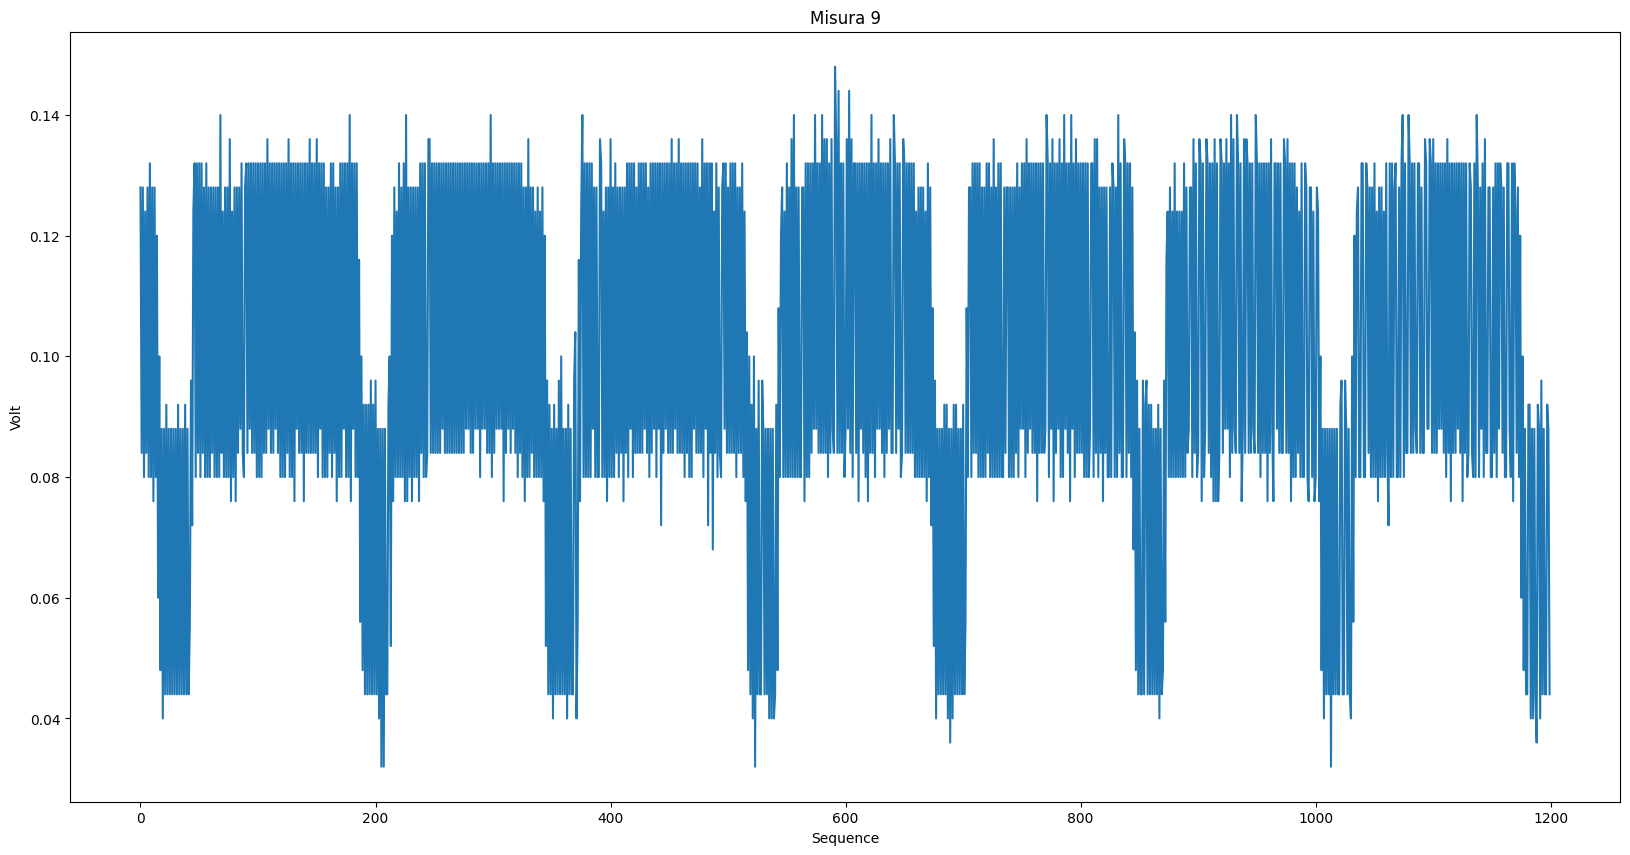

In [11]:
df=pd.read_csv('l3/NewFile3.csv', skiprows=2, names=['Sequence', 'Volt'], usecols=[0, 1])
plt.figure(figsize=(20, 10))
plt.plot(df['Sequence'], df['Volt'])
plt.xlabel('Sequence')
plt.ylabel('Volt')
plt.title('Misura 9')
plt.show()

In [ ]:
import pandas as pd
import numpy as np
l_1=0.854
def misura_g_pendolante(nome_file:str,lunghezza:float=l_1):
    # 1. Legge i metadati temporali dalla seconda riga del file
    meta = pd.read_csv(nome_file, nrows=1)
    t_start = float(meta['Start'].iloc[0])      # Istante iniziale (Start)
    dt = float(meta['Increment'].iloc[0])       # Passo di campionamento (Increment)

    # 2. Legge i campioni (Sequence e Volt) e ricostruisce il tempo di ogni punto
    df = pd.read_csv(nome_file, skiprows=2, names=['Sequence', 'Volt'], usecols=[0, 1])
    df['Tempo_s'] = t_start + df['Sequence'] * dt

    # 3. Individua le finestre dei picchi negativi (fronte di discesa sotto soglia)
    #soglia = -0.032  # Volt
    soglia=0.065
    sotto_soglia = df['Volt'] < soglia
    inizio_finestra = sotto_soglia & (~sotto_soglia.shift(1, fill_value=False))

    # Estrae solo i campioni di inizio finestra
    finestre = df.loc[inizio_finestra].copy()

    # 4. Calcola la distanza in campioni (Delta_n) e in secondi (Delta_t = Delta_n * dt)
    finestre['Delta_n'] = finestre['Sequence'].diff()
    finestre['Delta_t_s'] = finestre['Delta_n'] * dt

    print(f"Passo di campionamento (Increment): {dt} s (f_s = {1/dt:.1f} Hz)")
    print(f"Numero totale di finestre rilevate: {len(finestre)}\n")
    print(finestre[['Sequence', 'Tempo_s', 'Delta_n', 'Delta_t_s']].head(10).to_string(index=False))

    # 5. Stima del periodo T del pendolo (ogni passaggio corrisponde a mezzo periodo T/2)
    semi_periodi = finestre['Delta_t_s'].dropna()
    T_medio = 2 * semi_periodi.mean()
    T_err = 2 * semi_periodi.std(ddof=1) / np.sqrt(len(semi_periodi))

    print(f"\nSemi-periodo medio (T/2): {semi_periodi.mean():.4f} s")
    print(f"Periodo completo medio (T): {T_medio:.4f} ± {T_err:.4f} s")
    g=4*np.pi**2*lunghezza/T_medio**2
    g_err = g * (2 * T_err / T_medio)
    print(f"Accelerazione di gravità stimata: g = {g:.4f} ± {g_err:.4f} m/s²")
    return {"T_medio": T_medio, "T_err": T_err, "g": g, "g_err": g_err, "num_finestre": len(finestre)}

In [ ]:
misura_g_pendolante('mis_12.csv')

Passo di campionamento (Increment): 0.02 s (f_s = 50.0 Hz)
Numero totale di finestre rilevate: 28

 Sequence  Tempo_s  Delta_n  Delta_t_s
        0 -11.9994      NaN        NaN
       53 -10.9394     53.0       1.06
       93 -10.1394     40.0       0.80
      147  -9.0594     54.0       1.08
      185  -8.2994     38.0       0.76
      239  -7.2194     54.0       1.08
      279  -6.4194     40.0       0.80
      333  -5.3394     54.0       1.08
      372  -4.5594     39.0       0.78
      426  -3.4794     54.0       1.08

Semi-periodo medio (T/2): 0.8659 s
Periodo completo medio (T): 1.7319 ± 0.0925 s
Accelerazione di gravità stimata: g = 11.2408 ± 1.2010 m/s²


{'T_medio': np.float64(1.731851851851852),
 'T_err': np.float64(0.09251940127179524),
 'g': np.float64(11.240771786931935),
 'g_err': np.float64(1.201014364418966),
 'num_finestre': 28}

In [ ]:
ar_l1 = []
for i in range(1, 6):
    try:
        df=misura_g_pendolante(f'l1/mis_{i}.csv')
        print(f"\n\n--- Misura {i} ---")
        ar_l1.append(df)
    except Exception as e:
        print(f"file {i} non trovato: {e}")

ar_l1

Passo di campionamento (Increment): 0.05 s (f_s = 20.0 Hz)
Numero totale di finestre rilevate: 57

 Sequence  Tempo_s  Delta_n  Delta_t_s
       16 -29.1994      NaN        NaN
       36 -28.1994     20.0       1.00
       53 -27.3494     17.0       0.85
       73 -26.3494     20.0       1.00
       90 -25.4994     17.0       0.85
      110 -24.4994     20.0       1.00
      128 -23.5994     18.0       0.90
      148 -22.5994     20.0       1.00
      164 -21.7994     16.0       0.80
      185 -20.7494     21.0       1.05

Semi-periodo medio (T/2): 0.9286 s
Periodo completo medio (T): 1.8571 ± 0.0239 s
Accelerazione di gravità stimata: g = 9.7752 ± 0.2514 m/s²


--- Misura 1 ---
file 2 non trovato: [Errno 2] No such file or directory: 'mis_2.csv'
Passo di campionamento (Increment): 0.05 s (f_s = 20.0 Hz)
Numero totale di finestre rilevate: 64

 Sequence  Tempo_s  Delta_n  Delta_t_s
        7 -29.6494      NaN        NaN
       36 -28.1994     29.0       1.45
       57 -27.1494     21.0

[{'T_medio': np.float64(1.8571428571428572),
  'T_err': np.float64(0.02388516124383054),
  'g': np.float64(9.77522995900557),
  'g_err': np.float64(0.251443170209938),
  'num_finestre': 57},
 {'T_medio': np.float64(1.8746031746031744),
  'T_err': np.float64(0.03159590719703999),
  'g': np.float64(9.593982259959038),
  'g_err': np.float64(0.32340772409060065),
  'num_finestre': 64},
 {'T_medio': np.float64(1.8528301886792449),
  'T_err': np.float64(0.02620170913459771),
  'g': np.float64(9.82078879020398),
  'g_err': np.float64(0.27776042610431473),
  'num_finestre': 54},
 {'T_medio': np.float64(1.8523809523809522),
  'T_err': np.float64(0.024468217359080842),
  'g': np.float64(9.82555281001809),
  'g_err': np.float64(0.25957269914661457),
  'num_finestre': 253}]

for i in range 

$$l_2=88.0$$

In [ ]:
misura_g_pendolante('l3/NewFile7.csv',0.66)

Passo di campionamento (Increment): 0.05 s (f_s = 20.0 Hz)
Numero totale di finestre rilevate: 140

 Sequence  Tempo_s  Delta_n  Delta_t_s
        0 -29.9994      NaN        NaN
       15 -29.2494     15.0       0.75
       17 -29.1494      2.0       0.10
       31 -28.4494     14.0       0.70
       34 -28.2994      3.0       0.15
       47 -27.6494     13.0       0.65
       49 -27.5494      2.0       0.10
       63 -26.8494     14.0       0.70
       66 -26.6994      3.0       0.15
       81 -25.9494     15.0       0.75

Semi-periodo medio (T/2): 0.4263 s
Periodo completo medio (T): 0.8525 ± 0.0496 s
Accelerazione di gravità stimata: g = 35.8506 ± 4.1706 m/s²


{'T_medio': np.float64(0.8525179856115109),
 'T_err': np.float64(0.04958729618478012),
 'g': np.float64(35.85061185438952),
 'g_err': np.float64(4.170551093192558),
 'num_finestre': 140}

misu

$$l_3=66.1$$